In [1]:
import os, re, sys, json, shutil, cv2
import numpy as np
import pandas as pd
import torch
from PIL import Image

sys.path.append('../..')
sys.path.append('../../Model')    # O Blocks.index CARREGA A REDE PELO Network/ DE Model/
from Blocks.index import BlockPredictor, BlockSection, FaultStickExtractor, TileGrid, getBlockInfo, modelSummary, saveReport

cv2.setNumThreads(1)              # O DATALOADER CRIA WORKERS POR FORK DEPOIS DO CV2: SEM ISSO OS FILHOS TRAVAM
pd.set_option('display.max_columns', None)

In [ ]:
{'torch': torch.__version__, 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}

# CONFIGURAÇÃO
- Cada patch do Marlim é um slab de 64 inlines × 1601 × 2240 em 1 × 26 × 35 = 910 tiles de 128³ com 32 voxels de borda, float32 em `[0, 1]` (p01/p99 do bloco), eixos `(inline, z, xline)`, com a sísmica `<id>.png` e a interpretação `<id>_interpretado.png` da inline anotada ao lado
- `BASE_PATH` é a pasta dos modelos (`model_N/` com `info.json` e `model.pth`); `MODELS = []` pega todos os `model_N` dela
- `PATCH_IDS` são os patches avaliados; cada um é predito inteiro
- `SAVE_TILES = True` grava a máscara de cada tile em `masks/`, na mesma grade e no mesmo shape dos tiles de entrada (~7,3 GB por patch); `False` não grava nada por tile
- `SAVE_PRED = True` grava o `predicted.npy` do patch (64 × 1601 × 2240, ~0,9 GB)
- `SKIP_DONE = True` reaproveita o que já está em disco: um `predicted.npy` pronto dispensa a predição, e sem ele os tiles com `.dat` inteiro em `masks/` são lidos em vez de preditos
- `OVERLAP` e `WINDOW` controlam a janela deslizante; `WINDOW = None` usa a janela em que a rede foi treinada
- `STICK_TOL`, `STICK_MIN` e `STICK_GAP` são os botões do extrator, calibrados no patch 1200

In [3]:
BLOCK       = 'Marlim'
BASE_PATH   = '../../Model/Backup'                      # PASTA DOS MODELOS: '../../Model/Backup', '../../Documents/Backups/Marcia', ...
PATCHES_DIR = 'files/patches'                           # UMA PASTA POR PATCH: tiles/, <id>.png E <id>_interpretado.png
CACHE_DIR   = 'files/cache'
INDEX_PATH  = f'{CACHE_DIR}/inline_index.json'          # FATIA DA INLINE ANOTADA DE CADA PATCH
OUTPUT_DIR  = f'{BASE_PATH}/outputs/{BLOCK.lower()}'    # FIGURAS E TABELA DE TODOS OS MODELOS SELECIONADOS

MODELS          = []            # [] = TODOS OS MODELOS DE BASE_PATH
PATCH_IDS       = ['1200']
SAVE_TILES      = False         # True GRAVA A MÁSCARA DE CADA TILE EM masks/ (~7,3 GB POR PATCH)
SAVE_PRED       = True          # True GRAVA O predicted.npy DO PATCH (~0,9 GB)
SKIP_DONE       = True          # True REAPROVEITA O QUE JÁ ESTÁ EM DISCO (predicted.npy OU masks/)
OVERLAP         = 0.25          # SOBREPOSIÇÃO ENTRE JANELAS (0 = CORTE SECO, DO JEITO QUE O FORMAT CORTA O TREINO)
WINDOW          = None          # None = A JANELA DO TREINO (info.json); FORCE UMA TUPLA PARA TESTAR OUTRA, EX: (64, 64, 64)
MODEL_THRESHOLD = 0.5           # PROBABILIDADE A PARTIR DA QUAL O VOXEL ENTRA NA MÁSCARA

STICK_TOL = 0.80    # PERMISSIVIDADE DO EXTRATOR: 0 SÓ O TRAÇO ÓBVIO, 1 TUDO QUE PARECER FALHA
STICK_MIN = 140     # PX
STICK_GAP = 59      # PX: MAIOR LACUNA COSTURADA DENTRO DE UM STICK

models = MODELS or sorted((m for m in os.listdir(BASE_PATH) if re.fullmatch(r'model_\d+', m)), key=lambda n: int(n.split('_')[-1]))
models

['model_1']

# BLOCO
- `TileGrid` lê o `patch_metadata.json` e sabe onde o núcleo de cada tile (o tile sem os 32 voxels de borda) cai no volume, no mesmo corte em que os tiles foram gerados; o volume é montado pelos núcleos, com o shape do metadata, e um tile faltando levanta erro em vez de deixar buraco zerado
- `getBlockInfo` resume o bloco: shape inteiro, tamanho do tile, grade, total de tiles, quantos faltam em disco e o mínimo, máximo, média e desvio dos valores numa amostra de 100 tiles espalhados pela grade
- Tile normalizado (min-max ou p01/p99) fica em $[0, 1]$; padronizado fica com média 0 e desvio 1

In [4]:
grids = {pid: TileGrid(f'{PATCHES_DIR}/{pid}/tiles/patch_metadata.json') for pid in PATCH_IDS}
pd.concat([getBlockInfo(grids[pid], f'{PATCHES_DIR}/{pid}/tiles') for pid in PATCH_IDS], ignore_index=True)

,pasta,shape,tile,grade,tiles,faltando,amostra,min,max,media,desvio
0,files/patches/1200/tiles,"(64, 1601, 2240)","(128, 128, 128)","(1, 26, 35)",910,0,100,0.0,1.0,0.502452,0.142679


# MODELOS
- Rede, janela de treino, dataset e IoU de teste de cada modelo, lidos do `info.json`; o `rotulo` vai na legenda das figuras

In [5]:
pd.DataFrame([modelSummary(BASE_PATH, name) for name in models])

,nome,rede,janela,dataset,iou_teste,rotulo
0,model_1,dbrnet,128×128×128,dataset_74,0.7317,model_1 · dbrnet 128×128×128 (iou=0.732)


# PREDIÇÃO
- `BlockPredictor` cuida de um modelo: carrega os pesos só quando algum tile está pendente, e só se o `scaling` do treino for `'normalize'` ou `'percentile'` (o bloco está em `[0, 1]`)
- Cada tile passa pela `SlidingWindow` na janela do treino: as janelas se somam com peso de Hanning (~1 no centro, ~0 na borda) para a emenda não virar degrau, e o tile menor que a janela é espelhado
- O núcleo de cada tile predito vai direto para a inline das figuras e, com `SAVE_PRED`, para o `predicted.npy`; a tabela abaixo é quantos tiles a rodada cobre e quantos ainda faltam predizer

In [6]:
options    = {'overlap': OVERLAP, 'window': WINDOW, 'skipDone': SKIP_DONE, 'saveTiles': SAVE_TILES, 'savePred': SAVE_PRED}
predictors = {name: BlockPredictor(f'{BASE_PATH}/{name}', **options) for name in models}
pd.DataFrame([{'modelo': name, 'patch': pid, 'tiles': len(grids[pid].names()), 'pendentes': len(predictors[name].pending(grids[pid], f'{BASE_PATH}/{name}/{BLOCK.lower()}/patch_{pid}'))} for name in models for pid in PATCH_IDS])

,modelo,patch,tiles,pendentes
0,model_1,1200,910,910


# EXTRAÇÃO DE STICKS
- Cada falha de uma seção 2D vira uma reta (**stick**), a mesma representação para a rede e para o especialista
- **Evidência**: a probabilidade suavizada e reescalada para $[0,1]$; o piso sobe pelo percentil quando a predição é densa, para a teia não explodir o traçado
- **Votação tipo Hough**: a evidência somada numa janela reta de `seedLen` px em cada orientação plausível; os picos são as sementes
- **Traçado**: a semente se estende enquanto houver suporte, tolerando lacunas de até `STICK_GAP` px, e a reta é reajustada ao centro de massa da evidência por **PCA**
- **Filtros**: mergulho entre 43° e 76°, comprimento mínimo `STICK_MIN`, preenchimento, **energia sísmica** (a falha precisa cortar refletores, não a água nem a zona morta) e **ângulo com as camadas** pelo tensor de estrutura
- **Matching pursuit**: aceita a melhor reta, consome o corredor dela e segue para a próxima; no fim, retas colineares se fundem e as que correm por cima de uma maior saem
- A anotação do especialista entra pelo `fromRaster`: esqueleto, corte nas junções e cada pedaço endireitado até caber em 7 px de desvio

In [7]:
extractor = FaultStickExtractor(STICK_TOL, STICK_MIN, STICK_GAP)
experts   = {pid: np.array(Image.open(f'{PATCHES_DIR}/{pid}/{pid}_interpretado.png').convert('L')) > 128 for pid in PATCH_IDS}
pd.DataFrame(FaultStickExtractor.fromRaster(experts[PATCH_IDS[0]]))[['dip', 'len']].describe().round(1)

,dip,len
count,33.0,33.0
mean,61.0,225.9
std,10.7,134.7
min,29.9,35.4
25%,56.5,107.3
50%,62.2,219.7
75%,68.8,306.2
max,78.7,478.9


# COMPARAÇÃO COM O ESPECIALISTA
- A **inline anotada** de um patch não é a central: é a fatia do slab de maior correlação com o `<id>.png`, guardada em `files/cache` (`inline_index.json` e `real_center_<id>.npy`)
- `FaultComparer` estende a `BlockSection`: a interpretação entra como camada `expert`, e `recall` é a fração do comprimento anotado coberta pelos sticks preditos, `precisao` a fração do comprimento predito coberta pela anotação e `deteccao` a fração das falhas anotadas cobertas em pelo menos 50%, com casamento de 12 px e 20°
- A anotação é parcial (o especialista marca só as falhas principais), então `precisao` é limite inferior

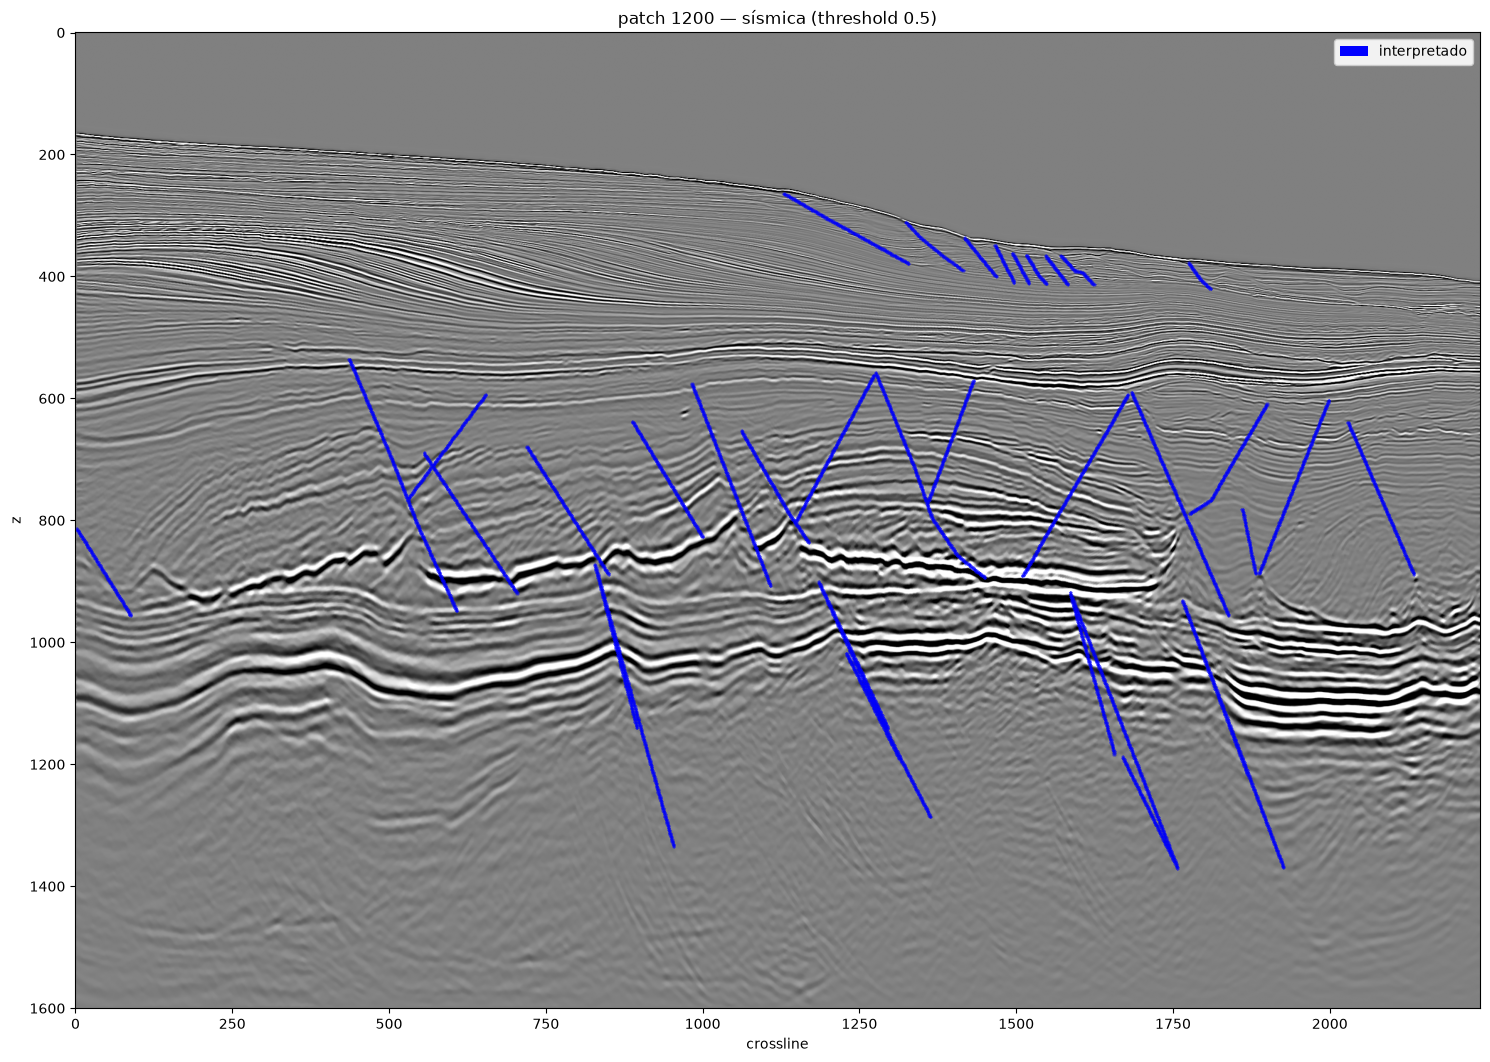

In [8]:
# INLINE ANOTADA DE UM PATCH, QUE NÃO É A CENTRAL: A FATIA DO SLAB DE MAIOR CORRELAÇÃO COM O <id>.png, GUARDADA EM files/cache
def annotatedInline(pid):
    table = json.load(open(INDEX_PATH)) if os.path.exists(INDEX_PATH) else {}
    cache = f'{CACHE_DIR}/real_center_{pid}.npy'

    if pid in table and os.path.exists(cache):
        return table[pid], np.load(cache)

    volume = grids[pid].reconstruct(f'{PATCHES_DIR}/{pid}/tiles', f'localizando inline {pid}')
    norm   = lambda a: (a - a.mean()) / (a.std() + 1e-9)
    target = norm(np.asarray(Image.open(f'{PATCHES_DIR}/{pid}/{pid}.png').convert('L'), np.float32))
    corr   = [float((norm(volume[k].astype(np.float32)) * target).mean()) for k in range(volume.shape[0])]
    index  = int(np.argmax(corr))
    print(f'[{pid}] inline anotada na fatia {index}/{volume.shape[0]} (r={max(corr):.3f})')

    os.makedirs(CACHE_DIR, exist_ok=True)
    np.save(cache, volume[index])
    json.dump({**table, pid: index}, open(INDEX_PATH, 'w'), indent=2)
    return index, volume[index].copy()


# CONVERGÊNCIA DOS STICKS DE UMA REDE COM OS DA CAMADA expert, A INTERPRETAÇÃO DO ESPECIALISTA
class FaultComparer(BlockSection):
    MATCH_TOL   = 12.0    # PX
    MATCH_ANGLE = 20.0    # GRAUS

    # COMPRIMENTO COBERTO NOS DOIS SENTIDOS; hit É A COBERTURA QUE CONTA UMA FALHA ANOTADA COMO DETECTADA
    def metrics(self, label, hit=0.5):
        mine, gt = self.sticks(label), self.sticks(self.reference())
        gtCov    = np.array([self.covered(g, mine) for g in gt])
        myCov    = np.array([self.covered(m, gt) for m in mine])
        gtLen    = np.array([g['len'] for g in gt])
        myLen    = np.array([m['len'] for m in mine])

        R = float((gtCov * gtLen).sum() / (gtLen.sum() + 1e-9))
        P = float((myCov * myLen).sum() / (myLen.sum() + 1e-9))
        return {
            'recall': round(R, 3),
            'deteccao': round(float((gtCov >= hit).mean()) if len(gtCov) else 0.0, 3),
            'precisao': round(P, 3),
            'f1': round(2 * R * P / (R + P + 1e-9), 3),
            'sticks': len(mine),
            'falhas_gt': len(gt),
            'len_p50': round(float(np.median(myLen)), 1) if len(myLen) else 0.0,
            'len_total': int(myLen.sum()),
            'len_total_gt': int(gtLen.sum())
        }

    # FRAÇÃO DO COMPRIMENTO DE a QUE PASSA A MENOS DE MATCH_TOL DE ALGUM DOS OUTROS, COM A MESMA DIREÇÃO
    def covered(self, a, others):
        P   = self.sample(a)
        hit = np.zeros(len(P), bool)

        for o in others:
            da = abs(self.angle(a) - self.angle(o)) % 180

            if min(da, 180 - da) > self.MATCH_ANGLE:
                continue

            p0, p1 = np.array(o['p0'], float), np.array(o['p1'], float)
            v      = p1 - p0
            t      = np.clip(((P - p0) @ v) / (v @ v + 1e-9), 0, 1)
            hit   |= np.linalg.norm(P - (p0 + t[:, None] * v), axis=1) <= self.MATCH_TOL

        return float(hit.mean())

    def reference(self):
        return next(label for label, layer in self.layers.items() if layer['expert'])

    @staticmethod
    def sample(s, step=1.0):
        p0, p1 = np.array(s['p0'], float), np.array(s['p1'], float)
        n = max(int(np.linalg.norm(p1 - p0) / step) + 1, 2)
        return p0 + (p1 - p0) * np.linspace(0, 1, n)[:, None]

    @staticmethod
    def angle(s):
        d = np.array(s['p1'], float) - np.array(s['p0'], float)
        return float(np.degrees(np.arctan2(d[1], d[0])) % 180)


inlines  = {pid: annotatedInline(pid) for pid in PATCH_IDS}
PATCH    = PATCH_IDS[0]
comparer = FaultComparer(inlines[PATCH][1], extractor, MODEL_THRESHOLD)
comparer.setSection('interpretado', experts[PATCH], 'blue', expert=True)
comparer.show('seismic', title=f'patch {PATCH}')

# PREDIÇÃO E FIGURAS POR MODELO
- Para cada modelo e cada patch de `PATCH_IDS`: prediz os tiles pendentes, mede a convergência com o especialista na inline anotada e grava as três figuras na pasta do patch (`predicted_seismic`, `predicted_mask`, `predicted_sticks`), copiadas para `OUTPUT_DIR` com o modelo e a rede no nome
- O `predicted.npy` é montado direto em disco por memmap e só ganha o nome final quando fica completo, então um arquivo interrompido nunca passa por pronto
- Um modelo sem `model.pth`, ou com `scaling` fora de `[0, 1]`, fica fora da tabela; a rede é solta antes do próximo modelo

In [ ]:
# PREDIZ UM PATCH COM UM MODELO, MEDE A CONVERGÊNCIA COM O ESPECIALISTA NA INLINE ANOTADA, SALVA AS TRÊS FIGURAS E DEVOLVE A LINHA DA TABELA
def comparePatch(name, pid):
    model           = modelSummary(BASE_PATH, name)
    patchDir        = f'{BASE_PATH}/{name}/{BLOCK.lower()}/patch_{pid}'
    inline, seismic = inlines[pid]
    values          = predictors[name].predict(grids[pid], f'{PATCHES_DIR}/{pid}/tiles', patchDir, inline)

    if values is None:
        return None

    comparer = FaultComparer(seismic, extractor, MODEL_THRESHOLD)
    comparer.setSection('interpretado', experts[pid], 'blue', expert=True)
    comparer.setSection(model['rotulo'], values, 'red')

    metrics = comparer.metrics(model['rotulo'])
    title   = f"Patch {pid} (Fatia {inline}) | Dataset: {str(model['dataset']).upper()} | Modelo: {name} ({model['rede']})"
    titles  = {'seismic': title, 'mask': title, 'sticks': f"{title} | Recall: {metrics['recall']:.2f} | Detecção: {metrics['deteccao']:.2f} | Precisão: {metrics['precisao']:.2f}"}

    for kind, text in titles.items():
        comparer.show(kind, title=text, save=f'{patchDir}/predicted_{kind}.png')
        shutil.copy(f'{patchDir}/predicted_{kind}.png', f'{OUTPUT_DIR}/{name}_{model["rede"]}_patch_{pid}_{kind}.png')

    run = json.load(open(f'{patchDir}/predict.json')) if os.path.exists(f'{patchDir}/predict.json') else {}
    return {'modelo': name, **{key: model[key] for key in ('rede', 'janela', 'iou_teste')}, 'overlap': run.get('overlap'), 'patch': pid, 'fatia': inline, **metrics}


os.makedirs(OUTPUT_DIR, exist_ok=True)
rows = []

for name in models:
    rows += [comparePatch(name, pid) for pid in PATCH_IDS]
    predictors[name].reset()

rows = [row for row in rows if row]
pd.DataFrame(rows)

# TABELA NA RAIZ
- `sticks_report.csv` fica em `OUTPUT_DIR` e junta as linhas novas às do CSV anterior: um par (modelo, patch) recalculado substitui o antigo, e rede, janela e IoU de teste são relidos do `info.json`

In [ ]:
saveReport(rows, f'{OUTPUT_DIR}/sticks_report.csv', BASE_PATH, 'patch', 'recall')